# MovieLens 1M：数据探索与预处理

本 Notebook 包含数据读取、质量检查、探索与可视化，以及可复现的时间划分、相关性标签、模型输入和评估协议。读取与划分函数位于 `src/data.py`，特征与评估上下文位于 `src/features.py`。

数据来源：[GroupLens MovieLens 1M](https://grouplens.org/datasets/movielens/1m/)。请阅读随附 README 并遵守数据使用条件。

## 1. 导入与定位项目

可从项目根目录或 `notebooks/` 目录启动。请选择安装了项目依赖的 Python 内核，然后按顺序运行全部单元格。

In [1]:
from pathlib import Path
import platform
import sys

import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(
    (path for path in [Path.cwd(), *Path.cwd().parents]
     if (path / 'src' / 'data.py').is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError('请从项目根目录或 notebooks 目录启动 Notebook。')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data import (
    column_summary, dataset_summary, load_movielens,
    quality_checks, resolve_data_dir,
)

print(f'Python: {platform.python_version()}')
print(f'pandas: {pd.__version__}')
print(f'Project root: {PROJECT_ROOT}')


Python: 3.11.17
pandas: 3.0.6
Project root: E:\港城莞\课程资料\研一 SemA\CS5481 Data Engineer\data_engineer_group_project


## 2. 读取三张原始表

读取器自动寻找 `data/ml-1m/`、`ml-1m/ml-1m/` 或 `ml-1m/`。如数据位于其他位置，将下面的 `DATA_DIR` 改为对应目录。

文件使用 `::` 分隔，使用 Latin-1 读取电影标题。邮编保持字符串以保留开头的 0；时间戳保持 Unix 秒数；年龄和职业保留官方编码；电影类型暂不拆分。

In [2]:
DATA_DIR = None  # 或指定目录，例如 'ml-1m/ml-1m'
data_dir = resolve_data_dir(DATA_DIR)
tables = load_movielens(data_dir)
users = tables['users']
movies = tables['movies']
ratings = tables['ratings']
print(f'Data directory: {data_dir}')

for name, frame in tables.items():
    print(f'\n{name}: {frame.shape[0]:,} rows, {frame.shape[1]} columns')
    display(frame.head())


Data directory: E:\港城莞\课程资料\研一 SemA\CS5481 Data Engineer\data_engineer_group_project\ml-1m\ml-1m

users: 6,040 rows, 5 columns


,user_id,gender,age,occupation,zip_code
0,1,F,1,10,48067
1,2,M,56,16,70072
2,3,M,25,15,55117
3,4,M,45,7,02460
4,5,M,25,20,55455



movies: 3,883 rows, 3 columns


,movie_id,title,genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama
4,5,Father of the Bride Part II (1995),Comedy



ratings: 1,000,209 rows, 4 columns


,user_id,movie_id,rating,timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968
3,1,3408,4,978300275
4,1,2355,5,978824291


## 3. 数据概况汇总

对比三张表的行数、列数、缺失值总数、含缺失值的列和完全重复的记录数。`duplicate_rows` 统计首次出现之后的重复行。实际统计结果以输出为准，不在读取函数中硬编码。

In [3]:
overview = dataset_summary(tables)
display(overview)


,rows,columns,missing_values,columns_with_missing,duplicate_rows
table,,,,,
users,6040,5,0,(none),0
movies,3883,3,0,(none),0
ratings,1000209,4,0,(none),0


## 4. 字段类型、缺失值与唯一值

`unique_values` 不包含缺失值。整数使用 pandas 的可空整数 `Int64`，方便发现缺失值；数值类型并不代表可直接作为连续特征使用，例如 `age` 和 `occupation` 实际是编码。

In [4]:
fields = column_summary(tables)
display(fields)

for name, frame in tables.items():
    print(f'\n{name}')
    frame.info()


dtype  missing_values  unique_values
table   column                                           
users   user_id      Int64               0           6040
        gender      string               0              2
        age          Int64               0              7
        occupation   Int64               0             21
        zip_code    string               0           3439
movies  movie_id     Int64               0           3883
        title       string               0           3883
        genres      string               0            301
ratings user_id      Int64               0           6040
        movie_id     Int64               0           3706
        rating       Int64               0              5
        timestamp    Int64               0         458455


users
<class 'pandas.DataFrame'>
RangeIndex: 6040 entries, 0 to 6039
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     6040 non-null   Int64 
 1   gender      6040 non-null   string
 2   age         6040 non-null   Int64 
 3   occupation  6040 non-null   Int64 
 4   zip_code    6040 non-null   string
dtypes: Int64(3), string(2)
memory usage: 253.8 KB

movies
<class 'pandas.DataFrame'>
RangeIndex: 3883 entries, 0 to 3882
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   movie_id  3883 non-null   Int64 
 1   title     3883 non-null   string
 2   genres    3883 non-null   string
dtypes: Int64(1), string(2)
memory usage: 94.9 KB

ratings
<class 'pandas.DataFrame'>
RangeIndex: 1000209 entries, 0 to 1000208
Data columns (total 4 columns):
 #   Column     Non-Null Count    Dtype
---  ------     --------------    -----
 0   user_id    1000209 non-null  

## 5. 评分范围与表间关联检查

检查用户/电影主键重复、用户与电影的重复评分对、超出 1–5 的评分、无法关联的用户/电影 ID，以及负时间戳。缺失字段单独在前面的汇总中报告。电影 ID 不要求连续，也不按最大 ID 推算电影数量。所有检查仅报告结果，不删除或修复记录。

In [5]:
checks = quality_checks(tables)
display(checks)
print(f"Observed rating range: {ratings['rating'].min()} to {ratings['rating'].max()}")

issues = checks.loc[checks['count'] > 0]
if issues.empty:
    print('上述基础质量检查未发现异常；缺失值请结合前面的概况表查看。')
else:
    print('发现需要进一步检查的记录，请根据上表决定后续处理方式。')


,count
check,
duplicate_user_ids,0
duplicate_movie_ids,0
duplicate_user_movie_pairs,0
ratings_outside_1_to_5,0
ratings_with_unknown_user,0
ratings_with_unknown_movie,0
negative_timestamps,0


Observed rating range: 1 to 5
上述基础质量检查未发现异常；缺失值请结合前面的概况表查看。


## 6. 探索设置与图表导出

以下分析使用完整数据描述评分行为和电影分布。所有结论中的数值由当前数据计算；这些全量统计仅用于探索，后续训练特征必须在数据划分后重新计算。

图表使用英文标题和坐标，分析说明使用中文。每张图同时保存为独立 PNG，统计表保存为 CSV，可直接用于报告。此阶段没有随机采样。

In [6]:
import math
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, StrMethodFormatter
from IPython.display import Markdown

%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False})
FIGURE_DIR = PROJECT_ROOT / 'outputs' / 'figures'
TABLE_DIR = PROJECT_ROOT / 'outputs' / 'tables'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)


def save_figure(fig, filename):
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / filename, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)


def save_table(frame, filename, *, index=True):
    frame.to_csv(TABLE_DIR / filename, index=index, encoding='utf-8-sig')


print(f'Matplotlib: {matplotlib.__version__}')
print(f'Figures: {FIGURE_DIR}')
print(f'Tables: {TABLE_DIR}')

Matplotlib: 3.11.2
Figures: E:\港城莞\课程资料\研一 SemA\CS5481 Data Engineer\data_engineer_group_project\outputs\figures
Tables: E:\港城莞\课程资料\研一 SemA\CS5481 Data Engineer\data_engineer_group_project\outputs\tables


## 7. 评分分布：用户是否倾向于给高分？

统计 1–5 分的数量和比例，并计算平均分及 4–5 分占比。这里的高分占比是描述性统计；相关性标签的阈值将在预处理阶段另行确定。

,count,share
rating,,
1,"56,174",5.62%
2,"107,557",10.75%
3,"261,197",26.11%
4,"348,971",34.89%
5,"226,310",22.63%


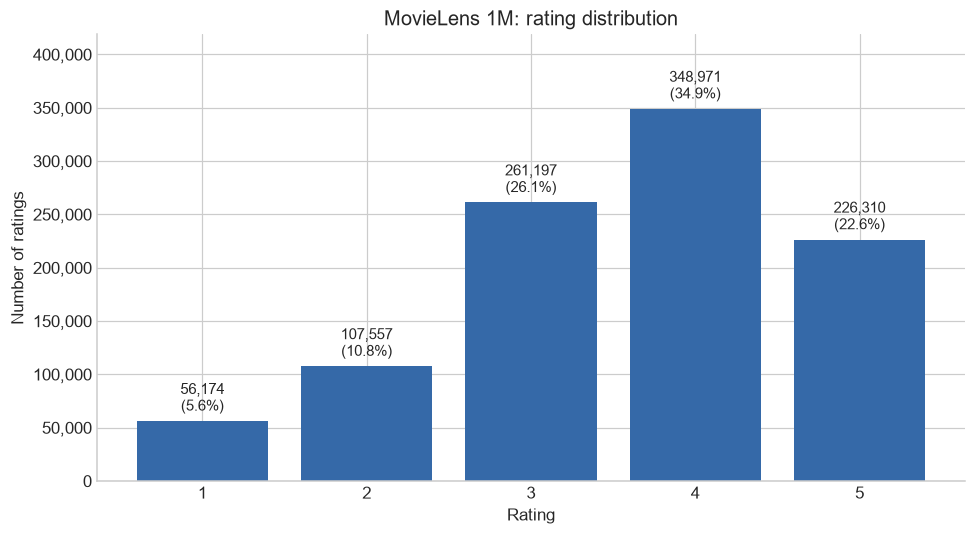

**结果解读：**平均评分为 **3.58**，4–5 分占全部评分的 **57.52%**。已记录评分整体偏向高分，评分行为并不均匀。后续应明确评分到相关性标签的转换规则，并区分低分记录与尚未评分的未知偏好。

In [7]:
rating_distribution = (ratings['rating'].value_counts()
                       .reindex(range(1, 6), fill_value=0)
                       .rename_axis('rating').to_frame('count'))
rating_distribution['share'] = rating_distribution['count'] / len(ratings)
mean_rating = float(ratings['rating'].mean())
high_rating_share = float(ratings['rating'].ge(4).mean())
display(rating_distribution.style.format({'count': '{:,.0f}', 'share': '{:.2%}'}))
save_table(rating_distribution, 'rating_distribution.csv')

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(rating_distribution.index.astype(str), rating_distribution['count'], color='#3569a8')
ax.bar_label(bars, labels=[f'{count:,}\n({share:.1%})'
                          for count, share in rating_distribution.itertuples(index=False)],
             padding=4, fontsize=10)
ax.set(title='MovieLens 1M: rating distribution', xlabel='Rating', ylabel='Number of ratings')
ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
ax.margins(y=0.20)
save_figure(fig, '01_rating_distribution.png')

display(Markdown(
    f'**结果解读：**平均评分为 **{mean_rating:.2f}**，4–5 分占全部评分的 '
    f'**{high_rating_share:.2%}**。已记录评分整体偏向高分，评分行为并不均匀。'
    '后续应明确评分到相关性标签的转换规则，并区分低分记录与尚未评分的未知偏好。'
))

## 8. 用户活跃度：每位用户有多少历史记录？

将全部用户纳入统计，展示评分数量的分布、均值、中位数和分位数。直方图纵轴使用对数刻度，以同时看清主要用户群和少数高度活跃用户。

,ratings_per_user
count,6040.00
mean,165.60
std,192.75
min,20.00
25%,44.00
50%,96.00
75%,208.00
90%,400.00
95%,556.00
99%,906.66


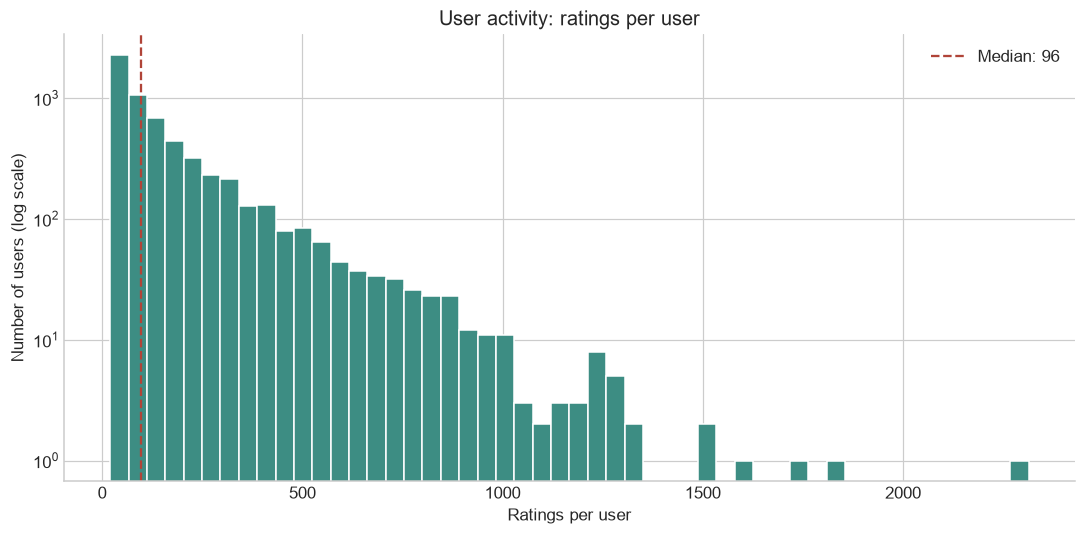

**结果解读：**每位用户平均有 **165.6** 条评分，中位数为 **96**，范围为 **20–2,314**。评分最多的前 10% 用户（604 人）贡献了 **38.09%** 的评分。均值高于中位数，说明少数活跃用户拉高了平均值。后续可以按历史长度分析模型效果；序列模型还需说明历史截断规则。这些用户均已有评分历史，不能用该数据直接证明系统对全新用户的效果。

In [8]:
user_activity = (ratings.groupby('user_id').size()
                 .reindex(users['user_id'], fill_value=0).rename('rating_count'))
user_activity_summary = user_activity.describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]).to_frame('ratings_per_user')
top_user_n = max(1, math.ceil(0.10 * len(user_activity)))
top_user_share = float(user_activity.nlargest(top_user_n).sum() / len(ratings))
display(user_activity_summary.round(2))
save_table(user_activity_summary, 'user_activity_summary.csv')

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(user_activity.to_numpy(dtype=int), bins=50, color='#3d8d83', edgecolor='white')
ax.axvline(float(user_activity.median()), color='#b04438', linestyle='--',
           label=f'Median: {user_activity.median():.0f}')
ax.set_yscale('log')
ax.set(title='User activity: ratings per user', xlabel='Ratings per user',
       ylabel='Number of users (log scale)')
ax.legend()
save_figure(fig, '02_user_activity.png')

display(Markdown(
    f'**结果解读：**每位用户平均有 **{user_activity.mean():.1f}** 条评分，'
    f'中位数为 **{user_activity.median():.0f}**，范围为 '
    f'**{user_activity.min():,}–{user_activity.max():,}**。评分最多的前 10% 用户'
    f'（{top_user_n:,} 人）贡献了 **{top_user_share:.2%}** 的评分。'
    '均值高于中位数，说明少数活跃用户拉高了平均值。'
    '后续可以按历史长度分析模型效果；序列模型还需说明历史截断规则。'
    '这些用户均已有评分历史，不能用该数据直接证明系统对全新用户的效果。'
))

## 9. 电影热度：评分是否集中在少数电影上？

电影数量分布包含电影表中的全部电影，未被评分的电影计为 0；热门榜按评分次数排序，评分次数相同则按电影 ID 升序。评分次数表示被评分的热度，不直接代表电影质量或每位用户的偏好。

,ratings_per_catalog_movie
count,3883.00
mean,257.59
std,379.39
min,0.00
25%,26.00
50%,109.00
75%,330.00
90%,706.60
95%,1032.80
99%,1756.76


,movie_id,title,genres,rating_count
0,2858,American Beauty (1999),Comedy|Drama,3428
1,260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Fantasy|Sci-Fi,2991
2,1196,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Drama|Sci-Fi|War,2990
3,1210,Star Wars: Episode VI - Return of the Jedi (1983),Action|Adventure|Romance|Sci-Fi|War,2883
4,480,Jurassic Park (1993),Action|Adventure|Sci-Fi,2672
5,2028,Saving Private Ryan (1998),Action|Drama|War,2653
6,589,Terminator 2: Judgment Day (1991),Action|Sci-Fi|Thriller,2649
7,2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller,2590
8,1270,Back to the Future (1985),Comedy|Sci-Fi,2583
9,593,"Silence of the Lambs, The (1991)",Drama|Thriller,2578


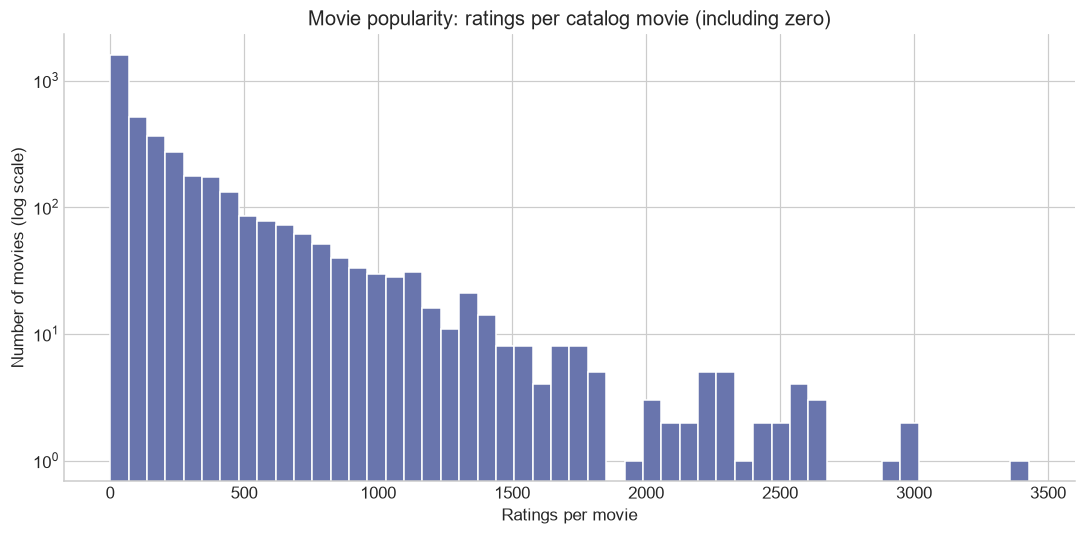

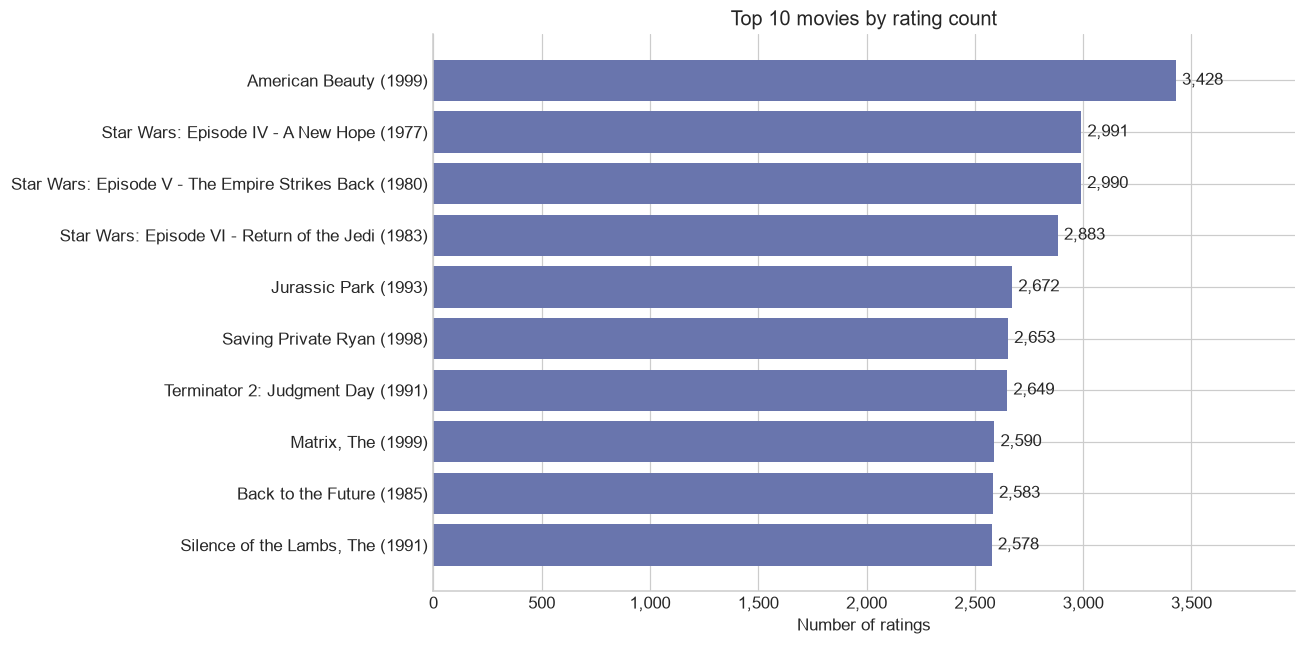

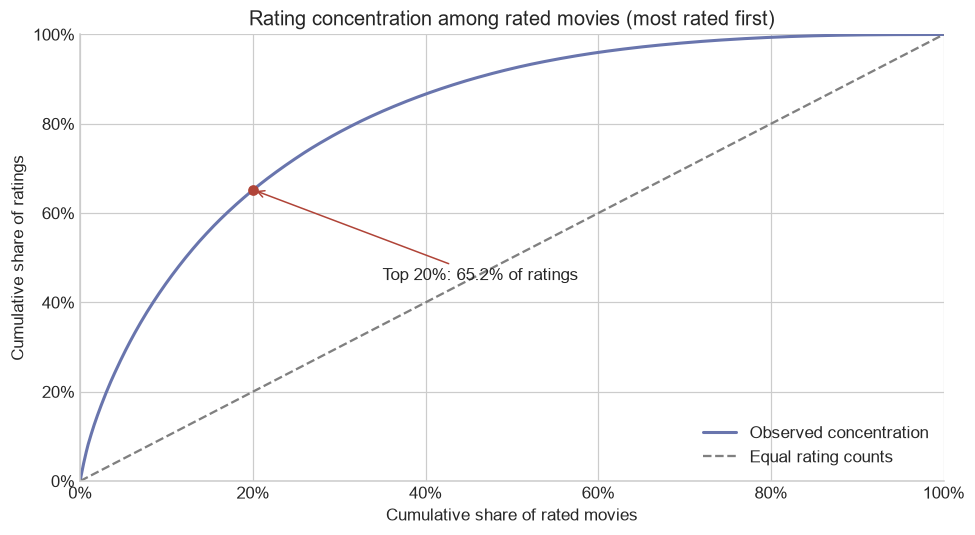

**结果解读：**电影表中有 **3,883** 部电影，其中 **177** 部没有任何评分。全部电影的评分次数中位数为 **109**，均值为 **257.6**。在 **3,706** 部有评分电影中，评分最多的前 20%（向上取整为 742 部）占全部评分的 **65.21%**。这表明交互集中在热门电影上，后续需要关注流行度偏差和长尾电影表现。暂无评分的电影缺少协同过滤依据，可在后续结合类型等内容特征讨论其推荐方式。

In [9]:
movie_counts = ratings.groupby('movie_id').size().rename('rating_count')
movie_stats = movies.merge(movie_counts.reset_index(), on='movie_id', how='left', validate='one_to_one')
movie_stats['rating_count'] = movie_stats['rating_count'].fillna(0).astype('int64')
movie_activity = movie_stats.set_index('movie_id')['rating_count']
movie_popularity_summary = movie_activity.describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]).to_frame('ratings_per_catalog_movie')
top_movies = (movie_stats.sort_values(['rating_count', 'movie_id'], ascending=[False, True])
              .head(10).reset_index(drop=True))
unrated_movie_count = int(movie_activity.eq(0).sum())
display(movie_popularity_summary.round(2))
display(top_movies[['movie_id', 'title', 'genres', 'rating_count']])
save_table(movie_popularity_summary, 'movie_popularity_summary.csv')
save_table(top_movies, 'top10_movies.csv', index=False)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(movie_activity.to_numpy(dtype=int), bins=50, color='#6975ad', edgecolor='white')
ax.set_yscale('log')
ax.set(title='Movie popularity: ratings per catalog movie (including zero)',
       xlabel='Ratings per movie', ylabel='Number of movies (log scale)')
save_figure(fig, '03_movie_popularity.png')

fig, ax = plt.subplots(figsize=(12, 6))
ordered_top_movies = top_movies.iloc[::-1]
bars = ax.barh(ordered_top_movies['title'], ordered_top_movies['rating_count'], color='#6975ad')
ax.bar_label(bars, labels=[f'{count:,}' for count in ordered_top_movies['rating_count']], padding=4)
ax.set(title='Top 10 movies by rating count', xlabel='Number of ratings', ylabel='')
ax.xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
ax.margins(x=0.16)
save_figure(fig, '04_top10_movies.png')

rated_movie_counts = movie_activity.loc[movie_activity.gt(0)].sort_values(ascending=False)
top_movie_n = max(1, math.ceil(0.20 * len(rated_movie_counts)))
top_movie_share = float(rated_movie_counts.iloc[:top_movie_n].sum() / rated_movie_counts.sum())
movie_fraction = [0.0] + [rank / len(rated_movie_counts) for rank in range(1, len(rated_movie_counts) + 1)]
rating_fraction = [0.0] + (rated_movie_counts.cumsum() / rated_movie_counts.sum()).tolist()
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(movie_fraction, rating_fraction, color='#6975ad', linewidth=2, label='Observed concentration')
ax.plot([0, 1], [0, 1], '--', color='gray', label='Equal rating counts')
ax.scatter([top_movie_n / len(rated_movie_counts)], [top_movie_share], color='#b04438', zorder=3)
ax.annotate(f'Top 20%: {top_movie_share:.1%} of ratings',
            xy=(top_movie_n / len(rated_movie_counts), top_movie_share),
            xytext=(0.35, 0.45), arrowprops={'arrowstyle': '->', 'color': '#b04438'})
ax.set(title='Rating concentration among rated movies (most rated first)',
       xlabel='Cumulative share of rated movies', ylabel='Cumulative share of ratings',
       xlim=(0, 1), ylim=(0, 1))
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend(loc='lower right')
save_figure(fig, '05_popularity_concentration.png')

display(Markdown(
    f'**结果解读：**电影表中有 **{len(movie_stats):,}** 部电影，其中 '
    f'**{unrated_movie_count:,}** 部没有任何评分。全部电影的评分次数中位数为 '
    f'**{movie_activity.median():.0f}**，均值为 **{movie_activity.mean():.1f}**。'
    f'在 **{len(rated_movie_counts):,}** 部有评分电影中，评分最多的前 20%'
    f'（向上取整为 {top_movie_n:,} 部）占全部评分的 **{top_movie_share:.2%}**。'
    '这表明交互集中在热门电影上，后续需要关注流行度偏差和长尾电影表现。'
    '暂无评分的电影缺少协同过滤依据，可在后续结合类型等内容特征讨论其推荐方式。'
))

## 10. 电影类型：哪些类型较多？

先按 `|` 拆分类型，再统计各类型包含的不同电影数；同一电影在同一类型中只计一次，但可同时属于多个类型。因此类型计数之和可以大于电影总数，各类型占电影目录的比例之和也可以超过 100%。该统计描述目录构成，不直接等同于用户喜好。

,movie_count,catalog_share
genre,,
Drama,"1,603",41.28%
Comedy,"1,200",30.90%
Action,503,12.95%
Thriller,492,12.67%
Romance,471,12.13%
Horror,343,8.83%
Adventure,283,7.29%
Sci-Fi,276,7.11%
Children's,251,6.46%


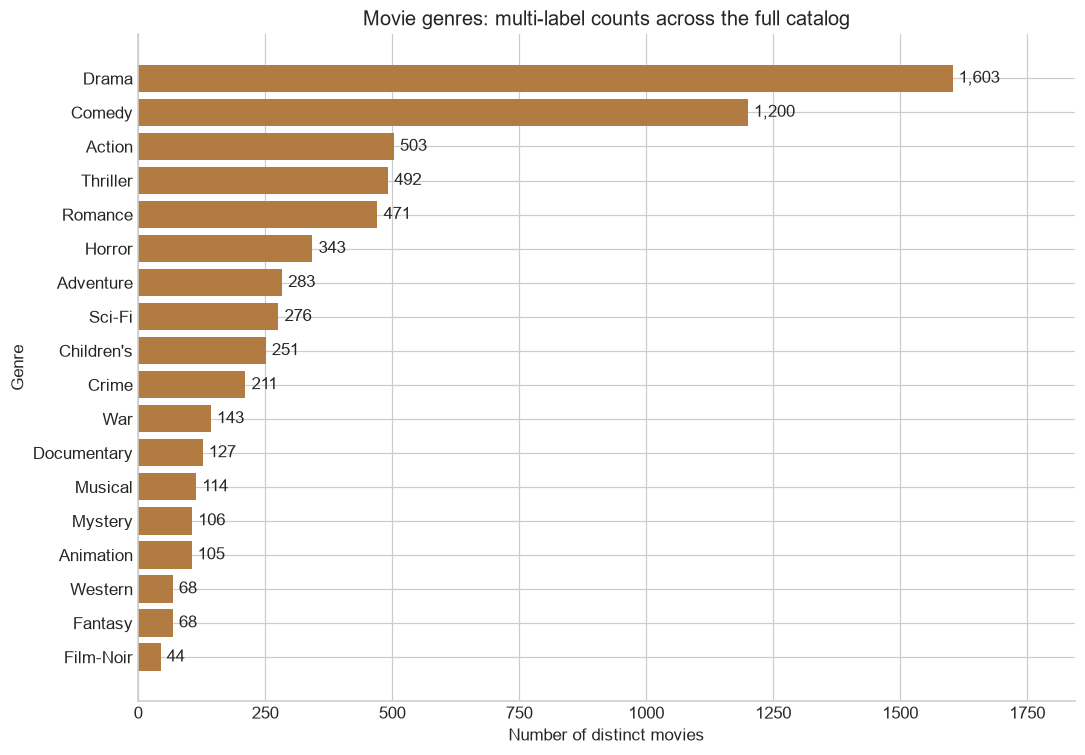

**结果解读：**拆分后共有 **18** 个类型，最多的是 **Drama**，包含 **1,603** 部电影。共统计到 **6,408** 个电影—类型关系。后续可对类型做多标签编码，作为 LightFM 等模型的电影特征；各类型数量不均衡，也应结合用户案例检查推荐结果是否过度集中在常见类型。

In [10]:
movie_genres = (movies[['movie_id', 'genres']]
                .assign(genre=movies['genres'].str.split('|', regex=False))
                .explode('genre').drop_duplicates(['movie_id', 'genre']))
genre_distribution = (movie_genres.groupby('genre')['movie_id'].nunique()
                      .sort_values(ascending=False).to_frame('movie_count'))
genre_distribution['catalog_share'] = genre_distribution['movie_count'] / movies['movie_id'].nunique()
display(genre_distribution.style.format({'movie_count': '{:,.0f}', 'catalog_share': '{:.2%}'}))
save_table(genre_distribution, 'genre_distribution.csv')

fig, ax = plt.subplots(figsize=(10, 7))
ordered_genres = genre_distribution.sort_values('movie_count')
bars = ax.barh(ordered_genres.index, ordered_genres['movie_count'], color='#b27b42')
ax.bar_label(bars, labels=[f'{count:,}' for count in ordered_genres['movie_count']], padding=4)
ax.set(title='Movie genres: multi-label counts across the full catalog',
       xlabel='Number of distinct movies', ylabel='Genre')
ax.margins(x=0.15)
save_figure(fig, '06_genre_distribution.png')

display(Markdown(
    f'**结果解读：**拆分后共有 **{len(genre_distribution)}** 个类型，最多的是 '
    f'**{genre_distribution.index[0]}**，包含 '
    f'**{int(genre_distribution.iloc[0]["movie_count"]):,}** 部电影。'
    f'共统计到 **{len(movie_genres):,}** 个电影—类型关系。'
    '后续可对类型做多标签编码，作为 LightFM 等模型的电影特征；'
    '各类型数量不均衡，也应结合用户案例检查推荐结果是否过度集中在常见类型。'
))

## 11. 交互稀疏度：多少用户—电影组合尚未评分？

交互密度 = 不同已评分用户—电影对数量 ÷（用户数 × 电影数），稀疏度 = 1 − 交互密度。分子按用户—电影对去重，避免重复记录抬高密度。

分别以全部目录电影和有评分电影为分母报告，两者不能混用。这里的“未观察到交互”是用户尚未评分，不是数据字段缺失，也不等于用户不喜欢电影。直接用计数计算，无需构建稠密矩阵。

,users,movies,possible_pairs,observed_pairs,density,sparsity
movie_universe,,,,,,
Full catalog,6040,3883,23453320,1000209,4.2647%,95.7353%
Rated movies only,6040,3706,22384240,1000209,4.4684%,95.5316%


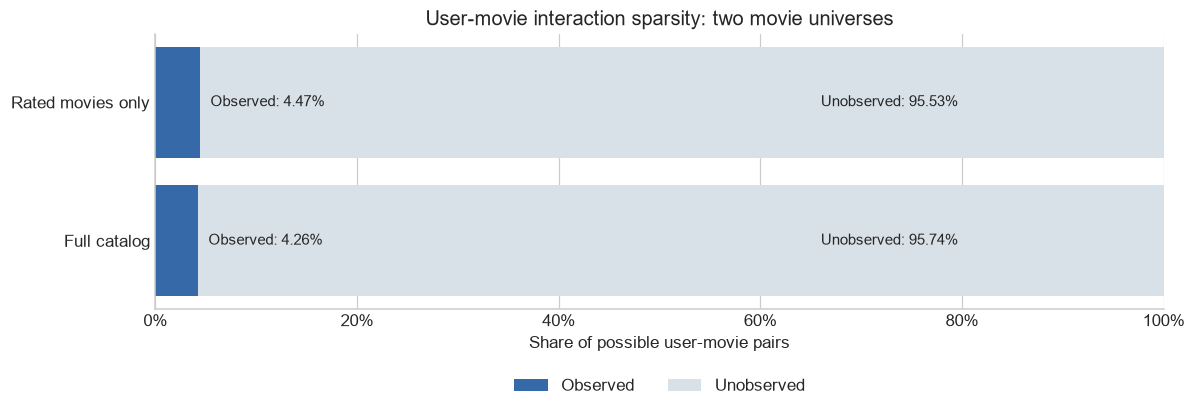

**结果解读：**按全部目录计算，**6,040** 名用户和 **3,883** 部电影共有 **23,453,320** 个可能交互，已观察到 **1,000,209** 个不同评分对。密度为 **4.2647%**，稀疏度为 **95.7353%**。仅考虑有评分电影时，稀疏度为 **95.5316%**。大量用户—电影组合仍是未知偏好，后续应采用稀疏表示，并在训练方案中明确负采样的含义。暂无评分电影属于本数据中的交互冷启动情况；时间划分之后，还须单独检查训练集中的冷启动用户和电影。

In [11]:
n_users = int(users['user_id'].nunique())
n_catalog_movies = int(movies['movie_id'].nunique())
n_rated_movies = int(ratings['movie_id'].nunique())
n_observed_pairs = int(ratings[['user_id', 'movie_id']].dropna().drop_duplicates().shape[0])
sparsity_rows = []
for universe, movie_count in [('Full catalog', n_catalog_movies), ('Rated movies only', n_rated_movies)]:
    possible_pairs = n_users * movie_count
    density = n_observed_pairs / possible_pairs
    sparsity_rows.append({'movie_universe': universe, 'users': n_users, 'movies': movie_count,
                          'possible_pairs': possible_pairs, 'observed_pairs': n_observed_pairs,
                          'density': density, 'sparsity': 1 - density})
sparsity_summary = pd.DataFrame(sparsity_rows).set_index('movie_universe')
display(sparsity_summary.style.format({'density': '{:.4%}', 'sparsity': '{:.4%}'}))
save_table(sparsity_summary, 'sparsity_summary.csv')

fig, ax = plt.subplots(figsize=(11, 4))
observed_pct = sparsity_summary['density'] * 100
unobserved_pct = sparsity_summary['sparsity'] * 100
ax.barh(sparsity_summary.index, observed_pct, color='#3569a8', label='Observed')
ax.barh(sparsity_summary.index, unobserved_pct, left=observed_pct, color='#d9e1e8', label='Unobserved')
for position, (_, row) in enumerate(sparsity_summary.iterrows()):
    ax.text(row['density'] * 100 + 1, position, f"Observed: {row['density']:.2%}", va='center', fontsize=10)
    ax.text(66, position, f"Unobserved: {row['sparsity']:.2%}", va='center', fontsize=10)
ax.set(title='User-movie interaction sparsity: two movie universes',
       xlabel='Share of possible user-movie pairs', xlim=(0, 100))
ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
save_figure(fig, '07_interaction_sparsity.png')

catalog_density = float(sparsity_summary.loc['Full catalog', 'density'])
catalog_sparsity = float(sparsity_summary.loc['Full catalog', 'sparsity'])
display(Markdown(
    f'**结果解读：**按全部目录计算，**{n_users:,}** 名用户和 '
    f'**{n_catalog_movies:,}** 部电影共有 **{n_users * n_catalog_movies:,}** 个可能交互，'
    f'已观察到 **{n_observed_pairs:,}** 个不同评分对。密度为 **{catalog_density:.4%}**，'
    f'稀疏度为 **{catalog_sparsity:.4%}**。仅考虑有评分电影时，稀疏度为 '
    f'**{sparsity_summary.loc["Rated movies only", "sparsity"]:.4%}**。'
    '大量用户—电影组合仍是未知偏好，后续应采用稀疏表示，并在训练方案中明确负采样的含义。'
    '暂无评分电影属于本数据中的交互冷启动情况；时间划分之后，还须单独检查训练集中的冷启动用户和电影。'
))

## 12. 探索结果汇总与下一步

下面的汇总表由以上统计生成，可直接用于报告。图表和汇总表随运行重新生成，原始评分记录保持不变。

In [12]:
eda_summary = pd.DataFrame([
    ('users', n_users, 'count'),
    ('catalog_movies', n_catalog_movies, 'count'),
    ('rated_movies', n_rated_movies, 'count'),
    ('unrated_catalog_movies', unrated_movie_count, 'count'),
    ('ratings', len(ratings), 'count'),
    ('mean_rating', mean_rating, 'stars'),
    ('rating_4_or_5_share', high_rating_share, 'fraction'),
    ('median_ratings_per_user', float(user_activity.median()), 'count'),
    ('top_10_percent_users_rating_share', top_user_share, 'fraction'),
    ('top_20_percent_rated_movies_rating_share', top_movie_share, 'fraction'),
    ('genres', len(genre_distribution), 'count'),
    ('full_catalog_density', catalog_density, 'fraction'),
    ('full_catalog_sparsity', catalog_sparsity, 'fraction'),
], columns=['metric', 'value', 'unit']).set_index('metric')
display(eda_summary)
save_table(eda_summary, 'eda_summary.csv')
print(f'Saved figures: {len(list(FIGURE_DIR.glob("*.png")))}')
print(f'Saved summary tables: {len(list(TABLE_DIR.glob("*.csv")))}')

,value,unit
metric,,
users,6.040000e+03,count
catalog_movies,3.883000e+03,count
rated_movies,3.706000e+03,count
unrated_catalog_movies,1.770000e+02,count
ratings,1.000209e+06,count
mean_rating,3.581564e+00,stars
rating_4_or_5_share,5.751608e-01,fraction
median_ratings_per_user,9.600000e+01,count
top_10_percent_users_rating_share,3.809274e-01,fraction


Saved figures: 7
Saved summary tables: 7


**探索结论：**高分较多、用户活跃度差异、电影热度集中和交互稀疏等特点，为标签定义、类型特征及分组评估提供依据。上面的全量统计仅用于描述性探索。下面开始预处理，训练用统计与特征仅使用训练集。

## 13. 清洗规则与处理审计

在副本中处理必要字段缺失、超出 1–5 分整数范围的评分、不可解析/负时间戳、未知用户/电影和完全重复的行。存在冲突的重复用户—电影对时停止，要求先明确处理策略。原始文件保持不变；原始评分和秒级时间戳保留，额外生成 UTC 时间列与原始行号 `event_id`。

当前计划：按用户时间约 80%/10%/10% 划分，评分至少 4 分为正反馈，统一评估 Top-10。这里先设置规则，实际标签在划分后生成。年龄、职业属于类别编码；本阶段只准备电影类型特征，不将人口属性强行作为连续数值归一化。

In [13]:
import hashlib
import numpy as np
import scipy
from src.data import (clean_ratings, chronological_split, add_relevance_labels,
                      split_summary, validate_splits)
from src.features import (build_model_inputs, build_evaluation_context,
                          evaluation_summary, save_preprocessed_artifacts)

SPLIT_RATIOS = (0.8, 0.1, 0.1)
RELEVANCE_THRESHOLD = 4
EVALUATION_K = 10

cleaned_ratings, cleaning_audit = clean_ratings(tables)
display(cleaning_audit)
removed_rows = int(cleaning_audit['removed_rows'].sum())
display(Markdown(
    f'**清洗结果：**输入 **{len(ratings):,}** 行，删除 **{removed_rows:,}** 行，'
    f'保留 **{len(cleaned_ratings):,}** 行。所有原始分数继续保留；'
    '不把未评分电影补成确定的负偏好。UTC 时间只用于清晰解释与检查，排序仍使用原始秒级时间戳。'
))

,removed_rows,remaining_rows
action,,
input,0,1000209
missing_required_fields,0,1000209
invalid_rating,0,1000209
invalid_timestamp,0,1000209
unknown_user,0,1000209
unknown_movie,0,1000209
exact_duplicate,0,1000209


**清洗结果：**输入 **1,000,209** 行，删除 **0** 行，保留 **1,000,209** 行。所有原始分数继续保留；不把未评分电影补成确定的负偏好。UTC 时间只用于清晰解释与检查，排序仍使用原始秒级时间戳。

## 14. 按用户评分时间划分训练、验证与测试

将同一用户同一时间戳的记录视为一个不可拆分的组。先在保证三个集合均有时间组的可行边界中选择最接近 80% 累计记录数的位置，再选择最接近 90% 的位置；距离相同时选较早边界。少于三个时间组的用户全部保留在训练集，实际比例以输出为准。

划分是确定性的，无需随机种子。它保证每个用户自己的历史先后，不是全局日期切分；不同用户的时间范围可能交叉。MovieLens 时间戳表示评分提交时间，不一定代表观影时间。

,target_share,actual_rows,actual_share
split,,,
train,80.00%,799086,79.89%
validation,10.00%,100613,10.06%
test,10.00%,100510,10.05%


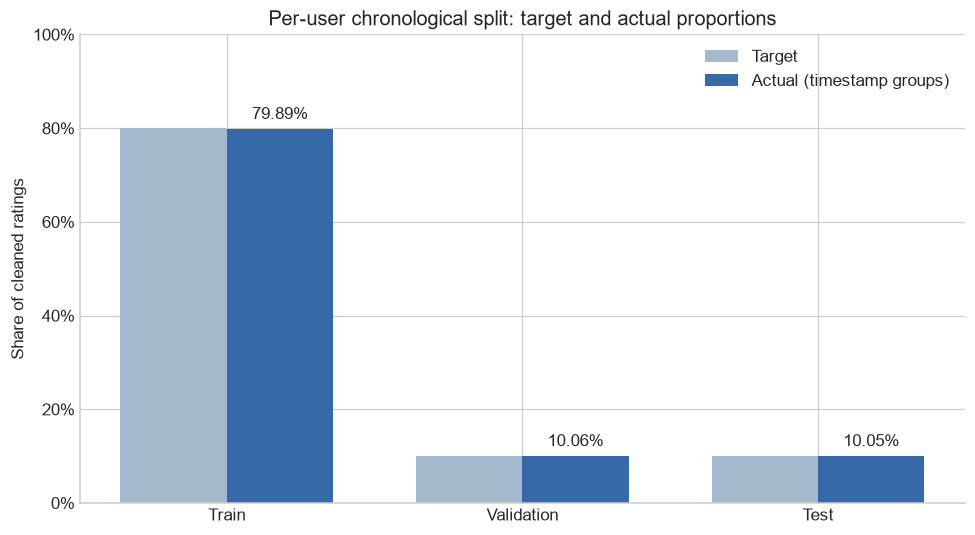

**划分说明：**有 **1** 位用户少于三个不同时间组，其记录全部保留在训练集；其余用户按上述时间组边界划分。为保持同时间戳记录完整，实际比例无需精确等于 80%/10%/10%。

In [14]:
splits = chronological_split(cleaned_ratings, SPLIT_RATIOS)
time_groups_per_user = cleaned_ratings.groupby('user_id')['timestamp'].nunique()
train_only_users = int(time_groups_per_user.lt(3).sum())
realized_ratios = pd.DataFrame({
    'target_share': SPLIT_RATIOS,
    'actual_rows': [len(splits[name]) for name in ['train', 'validation', 'test']],
}, index=pd.Index(['train', 'validation', 'test'], name='split'))
realized_ratios['actual_share'] = realized_ratios['actual_rows'] / len(cleaned_ratings)
display(realized_ratios.style.format({'target_share': '{:.2%}', 'actual_share': '{:.2%}'}))

fig, ax = plt.subplots(figsize=(9, 5))
positions = np.arange(3)
ax.bar(positions - 0.18, realized_ratios['target_share'] * 100, width=0.36,
       label='Target', color='#a5b9cd')
bars = ax.bar(positions + 0.18, realized_ratios['actual_share'] * 100, width=0.36,
              label='Actual (timestamp groups)', color='#3569a8')
ax.bar_label(bars, labels=[f'{value:.2%}' for value in realized_ratios['actual_share']], padding=4)
ax.set_xticks(positions, ['Train', 'Validation', 'Test'])
ax.set(title='Per-user chronological split: target and actual proportions',
       ylabel='Share of cleaned ratings', ylim=(0, 100))
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.legend()
save_figure(fig, '08_split_distribution.png')

display(Markdown(
    f'**划分说明：**有 **{train_only_users}** 位用户少于三个不同时间组，'
    '其记录全部保留在训练集；其余用户按上述时间组边界划分。'
    '为保持同时间戳记录完整，实际比例无需精确等于 80%/10%/10%。'
))

## 15. 相关性标签与划分检查

划分之后设置 `is_relevant = 1` 当且仅当原始评分至少 4 分。评分 1–3 的记录仍保留，用于显式评分模型及已评分电影过滤。标签 0 表示未达到正反馈阈值，不代表生成了未评分电影的负样本。

检查记录总数守恒、原始行号无重复/丢失、同时间戳与同用户—电影对不跨集合，以及每个用户的训练、验证、测试时间严格递增。冷启动用户/电影相对于训练集定义。

In [15]:
splits = add_relevance_labels(splits, RELEVANCE_THRESHOLD)
leakage_checks = validate_splits(splits, cleaned_ratings)
partition_summary = split_summary(splits)
display(partition_summary)
display(leakage_checks)
save_table(cleaning_audit, 'cleaning_audit.csv')
save_table(partition_summary, 'split_summary.csv')
save_table(leakage_checks, 'split_checks.csv')

display(Markdown(
    f'**检查结果：**所有 **{len(leakage_checks)}** 项划分检查均为 0 违规。'
    f'训练、验证和测试分别有 **{len(splits["train"]):,}**、'
    f'**{len(splits["validation"]):,}**、**{len(splits["test"]):,}** 条记录。'
    '上表中的各集合整体日期可能重叠，这与按用户时间划分的定义一致。'
))

,rows,row_share,users,movies,positive_rows,positive_share,cold_users,cold_movies,cold_movie_rows,first_rating_utc,last_rating_utc
split,,,,,,,,,,,
train,799086,0.798919,6040,3667,470016,0.588192,0,0,0,2000-04-25 23:05:32+00:00,2003-02-24 17:03:18+00:00
validation,100613,0.100592,6039,3372,53535,0.532088,0,17,18,2000-04-25 23:42:28+00:00,2003-02-25 15:48:25+00:00
test,100510,0.100489,6039,3442,51730,0.514675,0,27,36,2000-04-25 23:44:58+00:00,2003-02-28 17:49:50+00:00


,violations
check,
row_count_difference,0
duplicate_event_ids,0
missing_event_ids,0
unexpected_event_ids,0
timestamp_groups_crossing_splits,0
user_movie_pairs_crossing_splits,0
train_not_before_validation,0
validation_not_before_test,0
train_not_before_test,0


**检查结果：**所有 **9** 项划分检查均为 0 违规。训练、验证和测试分别有 **799,086**、**100,613**、**100,510** 条记录。上表中的各集合整体日期可能重叠，这与按用户时间划分的定义一致。

## 16. 构造训练期模型输入

用户/电影映射及电影类型词表只基于训练集涉及的实体。准备三类输入：显式评分稀疏矩阵（保留 1–5 分）、正反馈二值稀疏矩阵、电影类型多标签特征，以及每个用户的正反馈训练序列。

矩阵索引从 0 开始；序列 token 为 `movie_index + 1`，0 保留给 padding。序列保留全部正反馈训练历史，当前不截断。同时间戳内部按电影 ID 排序仅用于复现，不能将此顺序解释为实际观影先后。低分记录不进入正反馈序列，但仍用于已评分过滤。不同算法稍后通过适配代码使用这些共享输入。

In [16]:
model_inputs = build_model_inputs(splits['train'], movies)
model_input_summary = pd.DataFrame([
    ('explicit_ratings', *model_inputs.explicit_ratings.shape, model_inputs.explicit_ratings.nnz),
    ('positive_interactions', *model_inputs.positive_interactions.shape, model_inputs.positive_interactions.nnz),
    ('genre_features', *model_inputs.genre_features.shape, model_inputs.genre_features.nnz),
], columns=['input', 'rows', 'columns', 'nonzero_values']).set_index('input')
sequence_lengths = model_inputs.train_sequences['movie_tokens'].map(len)
sequence_summary = sequence_lengths.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).to_frame('positive_train_sequence_length')
train_positive_ids = set(splits['train'].loc[splits['train']['is_relevant'].eq(1), 'event_id'])
sequence_ids = {event_id for history in model_inputs.train_sequences['event_ids'] for event_id in history}
feature_isolation_checks = pd.DataFrame([
    ('mapped_users_outside_train', len(set(model_inputs.user_mapping['user_id']) - set(splits['train']['user_id']))),
    ('mapped_movies_outside_train', len(set(model_inputs.movie_mapping['movie_id']) - set(splits['train']['movie_id']))),
    ('explicit_nonzero_count_difference', abs(model_inputs.explicit_ratings.nnz - len(splits['train']))),
    ('positive_nonzero_count_difference', abs(model_inputs.positive_interactions.nnz - len(train_positive_ids))),
    ('sequence_events_outside_positive_train', len(sequence_ids - train_positive_ids)),
    ('positive_train_events_missing_from_sequences', len(train_positive_ids - sequence_ids)),
], columns=['check', 'violations']).set_index('check')
assert not feature_isolation_checks['violations'].any()
display(model_input_summary)
display(sequence_summary.round(2))
display(feature_isolation_checks)
save_table(model_input_summary, 'model_input_summary.csv')
save_table(sequence_summary, 'train_sequence_summary.csv')
save_table(feature_isolation_checks, 'feature_isolation_checks.csv')

display(Markdown(
    f'**输入结果：**训练映射包含 **{len(model_inputs.user_mapping):,}** 名用户、'
    f'**{len(model_inputs.movie_mapping):,}** 部电影及 **{len(model_inputs.genre_names)}** 个类型。'
    f'正反馈矩阵有 **{model_inputs.positive_interactions.nnz:,}** 个非零交互，'
    f'**{int(sequence_lengths.eq(0).sum())}** 位训练用户没有正反馈序列。'
    '上述对象均未使用验证或测试交互拟合；时间划分造成的新电影在下面单独报告。'
))

,rows,columns,nonzero_values
input,,,
explicit_ratings,6040,3667,799086
positive_interactions,6040,3667,470016
genre_features,3667,18,6145


,positive_train_sequence_length
count,6040.00
mean,77.82
std,86.96
min,0.00
50%,47.00
90%,182.00
95%,249.00
99%,405.61
max,1206.00


,violations
check,
mapped_users_outside_train,0
mapped_movies_outside_train,0
explicit_nonzero_count_difference,0
positive_nonzero_count_difference,0
sequence_events_outside_positive_train,0
positive_train_events_missing_from_sequences,0


**输入结果：**训练映射包含 **6,040** 名用户、**3,667** 部电影及 **18** 个类型。正反馈矩阵有 **470,016** 个非零交互，**2** 位训练用户没有正反馈序列。上述对象均未使用验证或测试交互拟合；时间划分造成的新电影在下面单独报告。

## 17. 共享候选、历史与可评估用户

验证只使用训练历史；测试使用训练加验证历史，模型参数仍固定为训练集学习的结果，不在此阶段重新训练。

三种算法共用训练电影目录作为候选全集，再过滤该用户当时已评分的所有电影（包括 1–3 分）。留出集中评分至少 4、位于训练目录且历史未评分的电影为可评估正例。

共同评估用户需要：有正反馈训练历史、至少一个可评估正例、至少 10 个候选。按顺序统计不满足条件的原因，确保各排除项互斥。冷电影正例单独报告；主要排名指标只能代表共同可评估子集，不能据此声称解决了全部冷启动问题。

评估上下文还提供对应阶段的已知正反馈序列 token；未知电影不进入训练词表。此阶段没有生成训练负样本，后续采样只根据训练期允许看到的信息定义。

In [17]:
evaluation_contexts = {
    stage: build_evaluation_context(splits, model_inputs, stage, k=EVALUATION_K)
    for stage in ['validation', 'test']
}
cohort_summary = evaluation_summary(evaluation_contexts)
display(cohort_summary)
save_table(cohort_summary, 'evaluation_cohorts.csv')
for stage, context in evaluation_contexts.items():
    assert int(context['eligible'].sum()) + int((~context['eligible']).sum()) == len(context)
    assert context.loc[context['eligible'], 'candidate_count'].ge(EVALUATION_K).all()

display(Markdown(
    f'**评估范围：**验证集共同可评估用户为 '
    f'**{cohort_summary.loc["validation", "eligible_users"]:,}** 人，测试集为 '
    f'**{cohort_summary.loc["test", "eligible_users"]:,}** 人。'
    '后续三种算法必须使用这些相同用户、候选规则和相关性标签；'
    '不能各自采用仓库默认的数据划分或采样候选来直接比较分数。'
))

,holdout_users,eligible_users,excluded_no_train_positive_history,excluded_no_warm_relevant_items,excluded_fewer_than_k_candidates,positive_pairs_with_cold_movie,eligible_relevant_pairs
stage,,,,,,,
validation,6039,5776,2,261,0,5,53530
test,6039,5765,2,272,0,13,51717


**评估范围：**验证集共同可评估用户为 **5,776** 人，测试集为 **5,765** 人。后续三种算法必须使用这些相同用户、候选规则和相关性标签；不能各自采用仓库默认的数据划分或采样候选来直接比较分数。

## 18. 保存本地模型输入与复现配置

交互级数据、序列和评估上下文保存到 `data/processed/`，该目录已加入 Git 忽略规则。各组员在本地运行生成，避免重新分发原始交互数据。报告用统计表保留在 `outputs/tables/`。

配置记录源文件 SHA-256、软件版本、目标比例、标签阈值、时间戳分组、候选和历史规则。当前流程没有随机步骤，`random_seed` 记为 `null`。后续模型训练和负采样需要另行记录种子与超参数。

In [18]:
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
preprocessing_config = {
    'dataset': 'MovieLens 1M',
    'source_sha256': {f'{name}.dat': hashlib.sha256((data_dir / f'{name}.dat').read_bytes()).hexdigest()
                      for name in ['users', 'movies', 'ratings']},
    'software': {'python': platform.python_version(), 'pandas': pd.__version__,
                 'numpy': np.__version__, 'scipy': scipy.__version__},
    'split_ratios': dict(zip(['train', 'validation', 'test'], SPLIT_RATIOS)),
    'split_method': 'per_user_nearest_feasible_cumulative_timestamp_groups',
    'boundary_tie_break': 'earlier_timestamp_group',
    'users_with_fewer_than_3_timestamp_groups': 'train_only',
    'train_only_user_count': train_only_users,
    'global_calendar_split': False,
    'relevance_threshold': RELEVANCE_THRESHOLD,
    'label_definition': 'rating >= relevance_threshold; original ratings retained',
    'mapping_fit_partition': 'train',
    'sequence_source': 'positive training interactions, ordered by timestamp then movie_id',
    'sequence_max_length': None,
    'padding_token': 0,
    'sequence_movie_token': 'movie_index + 1',
    'candidate_universe': 'all movies observed in train',
    'history_filter': 'exclude all previously rated movies, including low ratings',
    'validation_history': ['train'],
    'test_history': ['train', 'validation'],
    'model_fit_partitions': ['train'],
    'evaluation_k': EVALUATION_K,
    'evaluation_users': 'positive training history, warm positive target, at least k candidates',
    'cold_target_policy': 'reported separately, excluded from primary warm-target ranking metrics',
    'negative_sampling': 'not performed',
    'random_seed': None,
}
save_preprocessed_artifacts(splits, model_inputs, evaluation_contexts, PROCESSED_DIR, preprocessing_config)
print(f'Local model inputs: {PROCESSED_DIR}')
print(f'Input files: {len(list(PROCESSED_DIR.iterdir()))}')
display(Markdown(
    '**本阶段完成：**清洗与审计、按用户时间划分、相关性标签、训练期稀疏矩阵/类型特征/序列、'
    '共享候选与评估用户均已准备。下一步使用这些共享输入实现第一种推荐算法，'
    '在验证集上调参，并将测试集留给最终评估。'
))

Local model inputs: E:\港城莞\课程资料\研一 SemA\CS5481 Data Engineer\data_engineer_group_project\data\processed
Input files: 13


**本阶段完成：**清洗与审计、按用户时间划分、相关性标签、训练期稀疏矩阵/类型特征/序列、共享候选与评估用户均已准备。下一步使用这些共享输入实现第一种推荐算法，在验证集上调参，并将测试集留给最终评估。

数据引用：F. Maxwell Harper and Joseph A. Konstan. 2015. *The MovieLens Datasets: History and Context.* [DOI: 10.1145/2827872](https://doi.org/10.1145/2827872)。